In [1]:
!pip install -q tensorflow scikit-learn matplotlib pillow


In [2]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU available: True


In [9]:

import zipfile
import os

zip_path = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
)

extract_path = "/content/lung_cancer_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

print("\nFiles and folders:")
print(os.listdir(extract_path))


Dataset extracted successfully!
Location: /content/lung_cancer_dataset

Files and folders:
['The IQ-OTHNCCD lung cancer dataset']


In [10]:

import os

dataset_path = "/content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset"

print("Dataset folders:")
for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print(f"{item}  -->  {len(os.listdir(full_path))} items")
    else:
        print(item)


Dataset folders:
Malignant cases  -->  561 items
IQ-OTH_NCCD lung cancer dataset.txt
Normal cases  -->  416 items
Bengin cases  -->  120 items


In [12]:
import os
from PIL import Image
from collections import Counter
classes = {
    "Benign": "Bengin cases",
    "Malignant": "Malignant cases",
    "Normal": "Normal cases"
}

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")
total_images = 0

dataset_path = "/content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset"

for class_name, folder_name in classes.items():
    folder_path = os.path.join(dataset_path, folder_name)
    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(image_extensions)
    ]

    dimensions = Counter()
    valid_images = 0
    corrupted_images = []

    for filename in image_files:
        image_path = os.path.join(folder_path, filename)

        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1
                valid_images += 1
        except Exception:
            corrupted_images.append(filename)

    total_images += valid_images

    print(f"\n{class_name}")
    print("Valid images:", valid_images)
    print("Image dimensions:", dimensions.most_common(5))
    print("Corrupted images:", len(corrupted_images))

print("\nTotal valid images:", total_images)


Benign
Valid images: 120
Image dimensions: [((512, 512), 120)]
Corrupted images: 0

Malignant
Valid images: 561
Image dimensions: [((512, 512), 501), ((623, 512), 31), ((801, 512), 28), ((511, 404), 1)]
Corrupted images: 0

Normal
Valid images: 416
Image dimensions: [((512, 512), 415), ((506, 331), 1)]
Corrupted images: 0

Total valid images: 1097


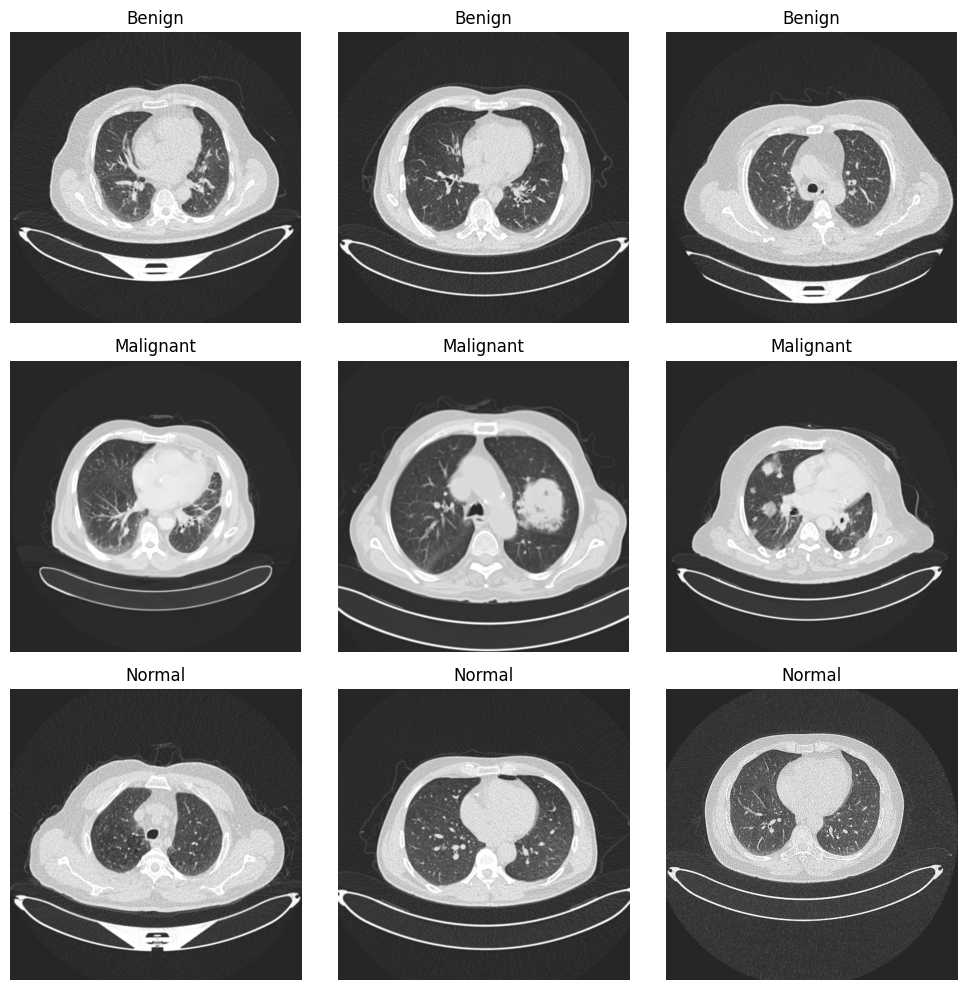

In [13]:

import os
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row, (class_name, folder_name) in enumerate(classes.items()):
    folder_path = os.path.join(dataset_path, folder_name)

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    for col in range(3):
        image_path = os.path.join(
            folder_path, image_files[col]
        )

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [14]:

import os

for class_name, folder_name in classes.items():
    folder_path = os.path.join(dataset_path, folder_name)

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    print(f"\n--- {class_name}: first 15 filenames ---")

    for filename in image_files[:15]:
        print(filename)



--- Benign: first 15 filenames ---
Bengin case (1).jpg
Bengin case (10).jpg
Bengin case (100).jpg
Bengin case (101).jpg
Bengin case (102).jpg
Bengin case (103).jpg
Bengin case (104).jpg
Bengin case (105).jpg
Bengin case (106).jpg
Bengin case (107).jpg
Bengin case (108).jpg
Bengin case (109).jpg
Bengin case (11).jpg
Bengin case (110).jpg
Bengin case (111).jpg

--- Malignant: first 15 filenames ---
Malignant case (1).jpg
Malignant case (10).jpg
Malignant case (100).jpg
Malignant case (101).jpg
Malignant case (102).jpg
Malignant case (103).jpg
Malignant case (104).jpg
Malignant case (105).jpg
Malignant case (106).jpg
Malignant case (107).jpg
Malignant case (108).jpg
Malignant case (109).jpg
Malignant case (11).jpg
Malignant case (110).jpg
Malignant case (111).jpg

--- Normal: first 15 filenames ---
Normal case (1).jpg
Normal case (10).jpg
Normal case (100).jpg
Normal case (101).jpg
Normal case (102).jpg
Normal case (103).jpg
Normal case (104).jpg
Normal case (105).jpg
Normal case (106).j

In [15]:

import os

for filename in os.listdir(dataset_path):
    if filename.lower().endswith(".txt"):
        file_path = os.path.join(dataset_path, filename)

        print("Documentation file:", filename)

        with open(file_path, "r", encoding="utf-8", errors="ignore") as file:
            print(file.read()[:5000])


Documentation file: IQ-OTH_NCCD lung cancer dataset.txt
The Iraq-Oncology Teaching Hospital/National Center for Cancer Diseases (IQ-OTH/NCCD) lung cancer dataset was collected in the above-mentioned specialist hospitals over a period of three months in fall 2019. It includes CT scans of patients diagnosed with lung cancer in different stages, as well as healthy subjects. IQ-OTH/NCCD slides were marked by oncologists and radiologists in these two centers. The dataset contains a total of 1190 images representing CT scan slices of 110 cases (see Figure 1). These cases are grouped into three classes: normal, benign, and malignant. of these, 40 cases are diagnosed as malignant; 15 cases diagnosed with benign; and 55 cases classified as normal cases. The CT scans were originally collected in DICOM format. The scanner used is SOMATOM from Siemens. CT protocol includes: 120 kV, slice thickness of 1 mm, with window width ranging from 350 to 1200 HU and window center from 50 to 600 were used for

In [16]:

import os

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for filename in files[:10]:
        print("  ", filename)

    if len(files) > 10:
        print("  ... and", len(files) - 10, "more files")



Folder: /content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset
   IQ-OTH_NCCD lung cancer dataset.txt

Folder: /content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset/Malignant cases
   Malignant case (189).jpg
   Malignant case (351).jpg
   Malignant case (550).jpg
   Malignant case (132).jpg
   Malignant case (89).jpg
   Malignant case (363).jpg
   Malignant case (61).jpg
   Malignant case (312).jpg
   Malignant case (329).jpg
   Malignant case (237).jpg
  ... and 551 more files

Folder: /content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset/Normal cases
   Normal case (357).jpg
   Normal case (341).jpg
   Normal case (195).jpg
   Normal case (285).jpg
   Normal case (218).jpg
   Normal case (135).jpg
   Normal case (62).jpg
   Normal case (35).jpg
   Normal case (352).jpg
   Normal case (242).jpg
  ... and 406 more files

Folder: /content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset/Bengin cases
   Bengin case (17).jpg
   Bengin case (21).jpg
   

In [10]:
import os
import zipfile
from sklearn.model_selection import train_test_split
from collections import Counter

dataset_path = "/content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset"
zip_path = "/content/archive (3).zip"

if not os.path.exists(dataset_path) and os.path.exists(zip_path):
    print("Dataset folder missing due to session reset. Re-extracting archive...")
    extract_path = "/content/lung_cancer_dataset"
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("Re-extraction completed!")

classes = {
    "Benign": "Bengin cases",
    "Malignant": "Malignant cases",
    "Normal": "Normal cases"
}

image_paths = []
labels = []

for label, folder_name in classes.items():
    folder_path = os.path.join(dataset_path, folder_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            image_paths.append(os.path.join(folder_path, filename))
            labels.append(label)

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Total images:", len(image_paths))
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining class counts:", Counter(y_train))
print("Validation class counts:", Counter(y_val))
print("Testing class counts:", Counter(y_test))

Dataset folder missing due to session reset. Re-extracting archive...
Re-extraction completed!
Total images: 1097
Training images: 767
Validation images: 165
Testing images: 165

Training class counts: Counter({'Malignant': 392, 'Normal': 291, 'Benign': 84})
Validation class counts: Counter({'Malignant': 84, 'Normal': 63, 'Benign': 18})
Testing class counts: Counter({'Malignant': 85, 'Normal': 62, 'Benign': 18})


In [11]:

import numpy as np
from PIL import Image

IMG_SIZE = (224, 224)

def load_images(paths):
    images = []

    for path in paths:
        with Image.open(path) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)
            images.append(np.array(img, dtype=np.float32) / 255.0)

    return np.array(images)

X_train_img = load_images(X_train)
X_val_img = load_images(X_val)
X_test_img = load_images(X_test)

print("Training images shape:", X_train_img.shape)
print("Validation images shape:", X_val_img.shape)
print("Testing images shape:", X_test_img.shape)

print("\nMinimum pixel value:", X_train_img.min())
print("Maximum pixel value:", X_train_img.max())


Training images shape: (767, 224, 224, 3)
Validation images shape: (165, 224, 224, 3)
Testing images shape: (165, 224, 224, 3)

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [12]:

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

y_train_cat = to_categorical(y_train_encoded, num_classes=3)
y_val_cat = to_categorical(y_val_encoded, num_classes=3)
y_test_cat = to_categorical(y_test_encoded, num_classes=3)

print("Class names:", list(label_encoder.classes_))
print("Training labels shape:", y_train_cat.shape)
print("Validation labels shape:", y_val_cat.shape)
print("Testing labels shape:", y_test_cat.shape)


Class names: [np.str_('Benign'), np.str_('Malignant'), np.str_('Normal')]
Training labels shape: (767, 3)
Validation labels shape: (165, 3)
Testing labels shape: (165, 3)


In [13]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_img,
    y_train_cat,
    validation_data=(X_val_img, y_val_cat),
    epochs=10,
    batch_size=16,
    callbacks=[early_stopping]
)


Epoch 1/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 18s 202ms/step - accuracy: 0.5580 - loss: 1.0346 - val_accuracy: 0.7091 - val_loss: 0.7606
Epoch 2/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7405 - loss: 0.6367 - val_accuracy: 0.8485 - val_loss: 0.4549
Epoch 3/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.8748 - loss: 0.3601 - val_accuracy: 0.9030 - val_loss: 0.1989
Epoch 4/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9087 - loss: 0.2107 - val_accuracy: 0.9818 - val_loss: 0.0999
Epoch 5/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9518 - loss: 0.1339 - val_accuracy: 0.9939 - val_loss: 0.0760
Epoch 6/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.9648 - loss: 0.0981 - val_accuracy: 0.9758 - val_loss: 0.0601
Epoch 7/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9752 - loss: 0.0782 - val_accuracy: 0.9939 - val_loss: 0.0346
Epoch 8/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9831 - loss: 0.0466 - val_accuracy: 0.9879 -

Test Accuracy: 98.18%
Test Loss: 0.0348

Classification Report:

              precision    recall  f1-score   support

      Benign       1.00      0.89      0.94        18
   Malignant       0.99      1.00      0.99        85
      Normal       0.97      0.98      0.98        62

    accuracy                           0.98       165
   macro avg       0.99      0.96      0.97       165
weighted avg       0.98      0.98      0.98       165



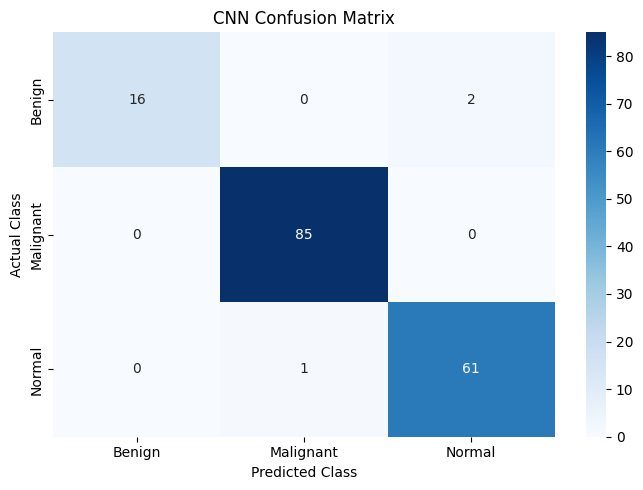

In [15]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(
    X_test_img, y_test_cat, verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predict the classes
predictions = model.predict(X_test_img, verbose=0)
y_pred = np.argmax(predictions, axis=1)
y_true = y_test_encoded

# Detailed evaluation
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()


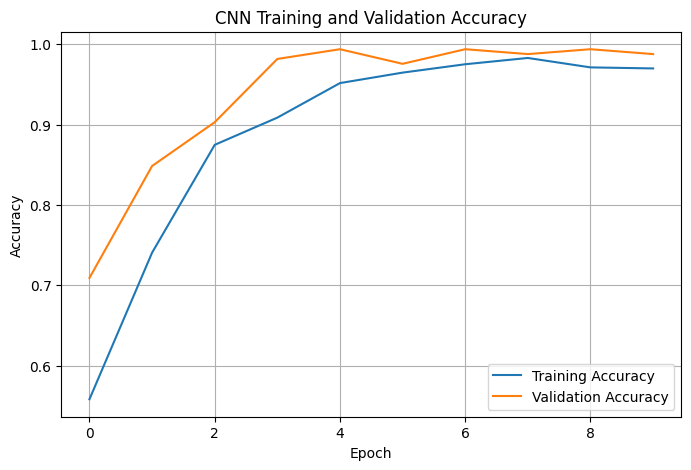

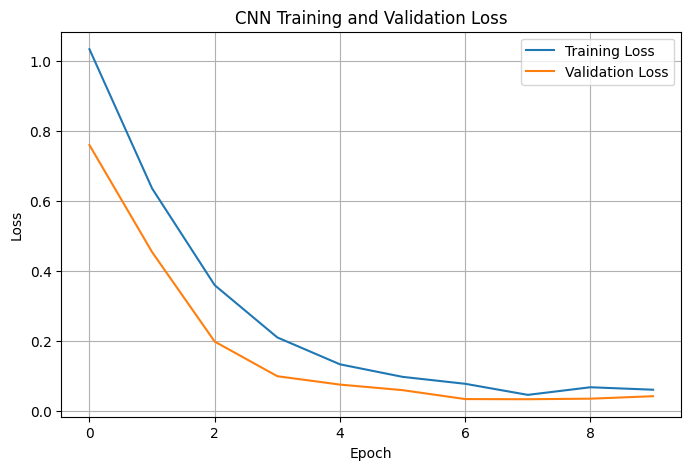

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [17]:

model.save("/content/lung_cancer_cnn.keras")

print("Model saved successfully!")


Model saved successfully!


In [19]:

from google.colab import files

files.download("/content/lung_cancer_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>